In [23]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
import numpy as np

data = load_iris(as_frame = True)
df = data.frame
dic = {x:y for x,y in zip(range(3), data.target_names)}
df['target'] = df['target'].map(dic)


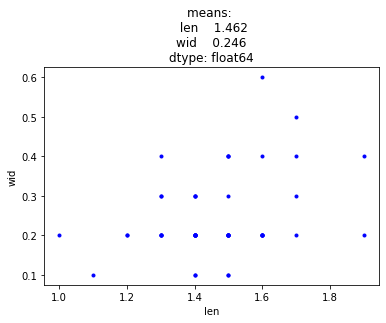

In [13]:
# Setosa petals
df_sp = df.query('target == "setosa"').filter(regex = 'petal').rename(columns = {'petal length (cm)':'len', 'petal width (cm)':'wid'})
plt.plot(df_sp.set_index('len'), ' .b')
plt.ylabel('wid')
plt.xlabel('len')
plt.title(f'means: \n {df_sp.mean()}')
df_sp.shape, df_sp.head()
plt.show()

,len,wid
0,-0.357011,-0.436492
1,-0.357011,-0.436492
2,-0.932836,-0.436492
3,0.218813,-0.436492
4,-0.357011,-0.436492


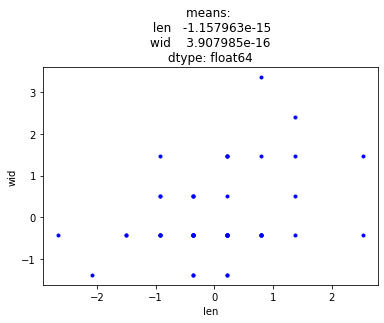

In [14]:
# normalized values for mean and std
df_spn = (
    df_sp.copy()
    .assign(len = lambda x:( x['len'] - x['len'].mean())/x['len'].std())
    .assign(wid = lambda x:( x['wid'] - x['wid'].mean())/x['wid'].std())
)
display(df_spn.head())
plt.plot(df_spn.set_index('len'), ' .b')
plt.ylabel('wid')
plt.xlabel('len')
plt.title(f'means: \n {df_spn.mean()}')
plt.show()

In [51]:
# relationship between len and wid:

# deviation: value minus mean
dl = df_sp['len'].values - df_sp['len'].mean() # deviation for length
dw = df_sp['wid'].values - df_sp['wid'].mean()

# variance: squared mean of deviation
var_l = np.mean(dl**2)
var_w = np.mean(dw**2)

# standard deviation: root square of variance
std_l = np.sqrt(np.mean(dl**2))
std_w = np.sqrt(np.mean(dw**2))
std_l, var_l

# covariance: mean of product of deviations
cov = np.mean(dl * dw)

# pearson: covariance divided by product of both standard deviations
pearson_corr = cov/(std_l*std_w)

In [52]:
# validation
print('validation!')
print(f'variance for len: numpy = {np.var(df_sp["len"], ddof = 0)}; manual = {var_l}')
print(f'std for len: numpy = {np.std(df_sp["len"], ddof = 0)}; manual = {std_l}')
print('\n')
print(f'variance for wid: numpy = {np.var(df_sp["wid"], ddof = 0)}; manual = {var_w}')
print(f'std for wid: numpy = {np.std(df_sp["wid"], ddof = 0)}; manual = {std_w}')
print('\n')
print(f'covariance: numpy = {np.cov(dl, dw, ddof = 0)[0,1]}, manual = {cov}')
print(f'pearson correlation: numpy = {np.corrcoef(dl, dw)[0,1]}, manual = {pearson_corr}')

validation!
variance for len: numpy = 0.029555999999999995; manual = 0.029555999999999995
std for len: numpy = 0.17191858538273283; manual = 0.17191858538273283


variance for wid: numpy = 0.010883999999999998; manual = 0.010883999999999998
std for wid: numpy = 0.1043264108459598; manual = 0.1043264108459598


covariance: numpy = 0.005948000000000001, manual = 0.005948000000000001
pearson correlation: numpy = 0.3316300408041188, manual = 0.3316300408041188


In [94]:
# prediction time!
a1_xl = cov/var_l
a0_xl = np.mean(df_sp['wid']) - (cov/var_l) * np.mean(df_sp['len'])

a1_xw = cov/var_w

cov/(var_l), cov/(var_w)

(0.20124509405873603, 0.5464902609334805)

In [95]:
# validation:
print(f'if x/independent variable is len: numpy = {np.polyfit(x = df_sp["len"], y = df_sp["wid"], deg = 1)}, manual = {a1_xl, a0_xl}')
print(f'if x/independent variable is wid: numpy = {np.polyfit(y = df_sp["len"], x = df_sp["wid"], deg = 1)[0]}, manual = {a1_xw}')

if x/independent variable is len: numpy = [ 0.20124509 -0.04822033], manual = (0.20124509405873603, -0.04822032751387215)
if x/independent variable is wid: numpy = 0.5464902609334812, manual = 0.5464902609334805


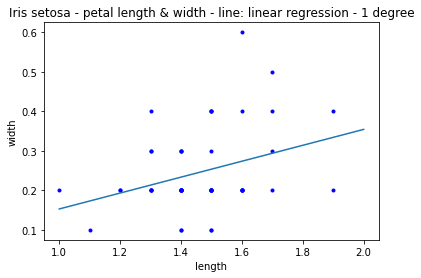

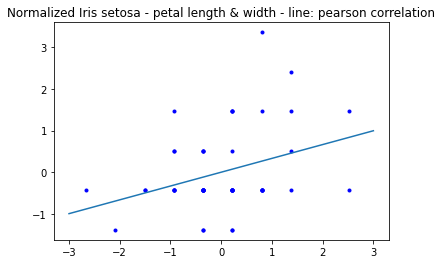

In [113]:
# sth cool: the normalized data with pvalue instead of slope is very similar to the real data with regression!
plt.plot(df_sp.set_index('len'), ' .b')
plt.plot([1,2],[1*a1_xl + a0_xl, 2*a1_xl + a0_xl])
plt.ylabel('width')
plt.xlabel('length')
plt.title('Iris setosa - petal length & width - line: linear regression - 1 degree')
plt.show()
plt.plot(df_spn.set_index('len'), ' .b')
plt.plot([-3,3], [-3 * pearson_corr, 3*pearson_corr])
plt.title('Normalized Iris setosa - petal length & width - line: pearson correlation')
plt.show()

#### deviation, residuals and r_squared
```python

residuals = y_model - y_data
RSS = np.sum(np.square(residuals))

mean_squared_residuals = np.sum(np.square(residuals))/len(residuals)
MSE = np.mean(np.square(residuals))
RMSE = np.sqrt(np.mean(np.square(residuals)))
RMSE = np.std(residuals)

####

deviations = np.mean(y_data) - y_data
VAR = np.sum(np.square(deviations))

residuals = y_model - y_data
RSS = np.sum(np.square(residuals))

r_squared = 1 - (RSS / VAR)
r = correlation(y_data, y_model)
```

In [130]:
df_sp_pr = df_sp.copy()
df_sp_pr['pred_wid_manual'] = df_sp_pr['len']*a1_xl + a0_xl

from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X = df_sp_pr[['len']], y = df_sp_pr['wid'])
df_sp_pr['pred_wid_sklearn'] = reg.predict(df_sp_pr[['len']])
df_sp_pr['is_diff'] = np.isclose(df_sp_pr['pred_wid_manual'],df_sp_pr['pred_wid_sklearn'])
df_sp_pr.head()




,len,wid,pred_wid_manual,pred_wid_sklearn,is_diff
0,1.4,0.2,0.233523,0.233523,True
1,1.4,0.2,0.233523,0.233523,True
2,1.3,0.2,0.213398,0.213398,True
3,1.5,0.2,0.253647,0.253647,True
4,1.4,0.2,0.233523,0.233523,True


In [157]:
rw = df_sp_pr['wid'] - df_sp_pr['pred_wid_manual'] # residual
rss_w = np.sum(np.square(rw)) # rss
mse_w = np.mean(np.square(rw)) # mse
rmse_w = np.sqrt(np.mean(np.square(rw))) # rmse
r_squared = 1 - (mse_w/var_w) # r_squared


(0.4843497090269319,
 0.009686994180538639,
 0.0984225288261719,
 0.10997848396374121)

In [166]:
# validation:
print(f'r_squred: from sklearn: {reg.score(X = df_sp_pr[["len"]],y = df_sp_pr["wid"])}, from model: {r_squared}')

r_squred: from sklearn: 0.10997848396374132, from model: 0.10997848396374121


In [155]:
(np.mean((rw - np.mean(rw))**2))**(1/2)

0.09842252882617189

In [163]:
reg.score(X = df_sp_pr[['len']],y = df_sp_pr['wid'])

0.10997848396374132

In [164]:
reg.score?